# Native compilation

Real hardware runs only its native gates. Each twin compiles your circuit to its vendor's gate set from first
principles, with no vendor SDK, and proves the result is exact.

The compiled circuits are drawn with the same compiler the workers use, because the API returns statistics rather than
the circuit. `draw_native` raises an error if that drawing disagrees with the gate counts in the job's API response.

QPUTwin at http://localhost:8000: ready, 7 twins reachable


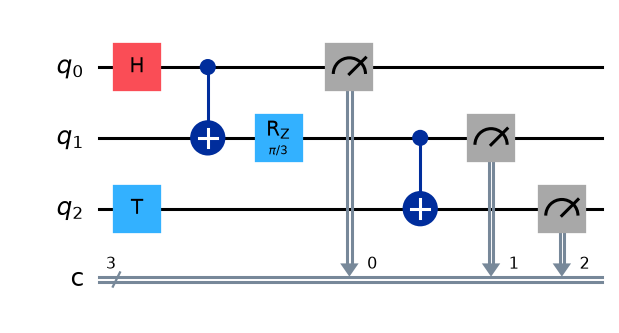

In [1]:
from qputwin_demo import *

connect()
circuit = HEADER + """qreg q[3];
creg c[3];
h q[0];
t q[2];
cx q[0],q[1];
rz(pi/3) q[1];
cx q[1],q[2];
measure q -> c;
"""
draw(circuit)

In [2]:
results = {backend: run(backend, circuit, shots=2048) for backend in BACKENDS}

## One circuit, four native forms

### Quantinuum Helios: `u1q`, `rz`, `zzmax`

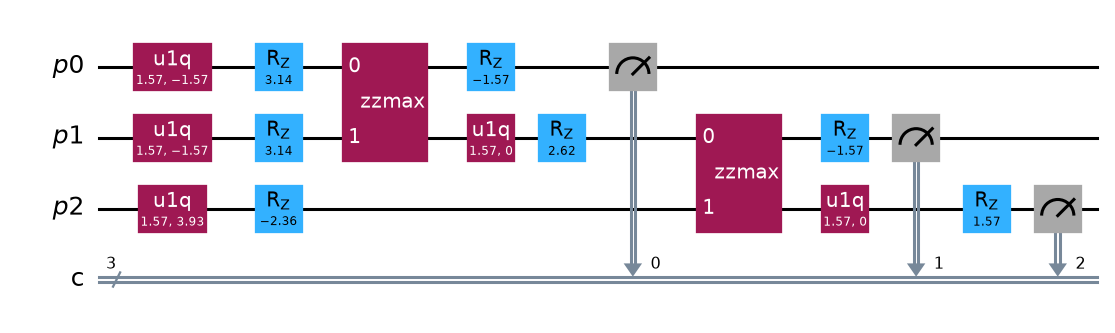

In [3]:
draw_native(results["quantinuum_helios"], circuit)

### IonQ Forte: `gpi`, `gpi2`, `rz`, `ms`

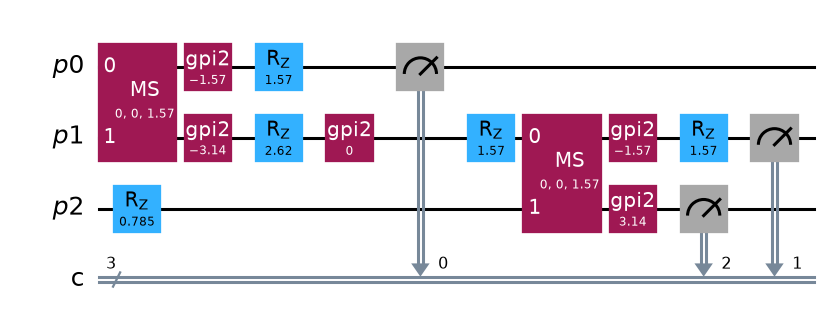

In [4]:
draw_native(results["ionq_forte"], circuit)

### Rigetti Ankaa-3: `rx`, `rz`, `cz`

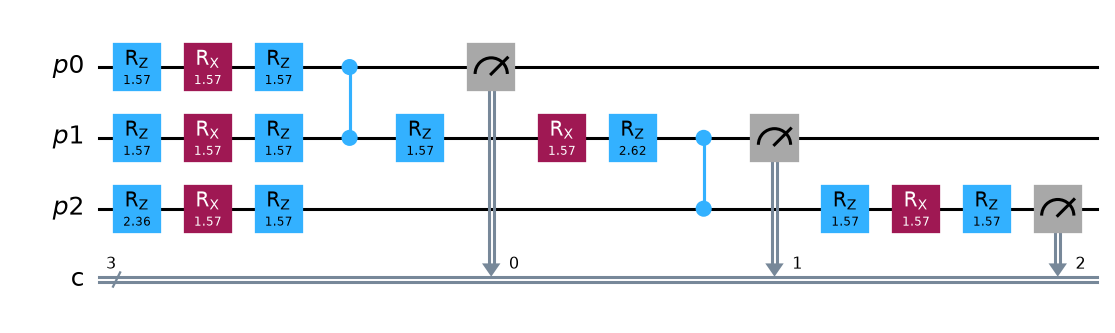

In [5]:
draw_native(results["rigetti_ankaa_3"], circuit)

### IQM Emerald: `prx`, `rz`, `cz`

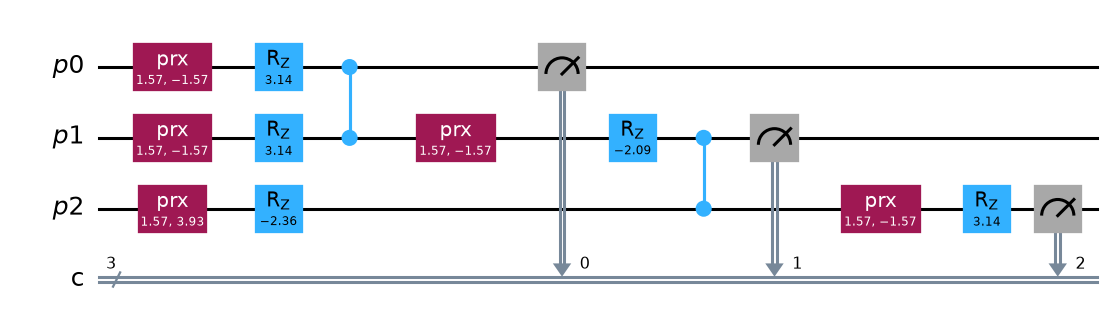

In [6]:
draw_native(results["iqm_emerald"], circuit)

## Every job carries a certificate

`max_synthesis_error` compares each compiled piece with its source, global phase included. Compilation is exact,
so this stays near machine precision. All four results must also give the same ideal distribution.

In [7]:
reference = ideal_counts(circuit)

pd.DataFrame({NAMES[b]: {
    "Input gates": r["compilation"]["input_gate_count"],
    "Native operations": r["compilation"]["native_op_count"],
    "Physical pulses": r["compilation"]["native_physical_op_count"],
    "Virtual rz": r["compilation"]["native_virtual_op_count"],
    "Two-qubit gates": r["compilation"]["native_two_qubit_count"],
    "Native depth": r["compilation"]["native_depth"],
    "Certificate error": f"{r['compilation']['max_synthesis_error']:.1e}",
    "Fidelity to reference": round(hellinger(reference, r["result"]["counts"]), 4),
} for b, r in results.items()}).T

,Input gates,Native operations,Physical pulses,Virtual rz,Two-qubit gates,Native depth,Certificate error,Fidelity to reference
Helios,5,14,7,7,2,6,2.5e-16,0.9999
Forte,5,12,7,5,2,6,3.5e-16,0.9999
Ankaa-3,5,17,7,10,2,6,3.3e-16,0.9999
Emerald,5,12,7,5,2,6,3.9e-16,0.9999


## Gate cost of a standard gate

A Toffoli is not native anywhere. Its cost in native two-qubit gates shows what each gate set pays for.

In [8]:
toffoli = HEADER + "qreg q[3];\ncreg c[3];\nh q[0];\nh q[1];\nccx q[0],q[1],q[2];\nmeasure q -> c;\n"
rows = {}
for backend in BACKENDS:
    r = run(backend, toffoli, routing=True)
    rows[NAMES[backend]] = r["compilation"]["native_gate_histogram"] | {"swaps": r["compilation"]["routing"].get("swaps_inserted", 0)}
pd.DataFrame(rows).T.fillna(0).astype(int)

,rz,u1q,zzmax,swaps,gpi2,ms,cz,rx,prx
Helios,14,9,6,0,0,0,0,0,0
Forte,10,0,0,0,15,6,0,0,0
Ankaa-3,30,0,0,1,0,0,9,16,0
Emerald,10,0,0,1,0,0,9,0,12


## How long would this take on the device?

The ASAP scheduler places every native gate in time. Most durations are assumed, so read this as an order-of-magnitude
estimate. The robust result is the gap between technologies.

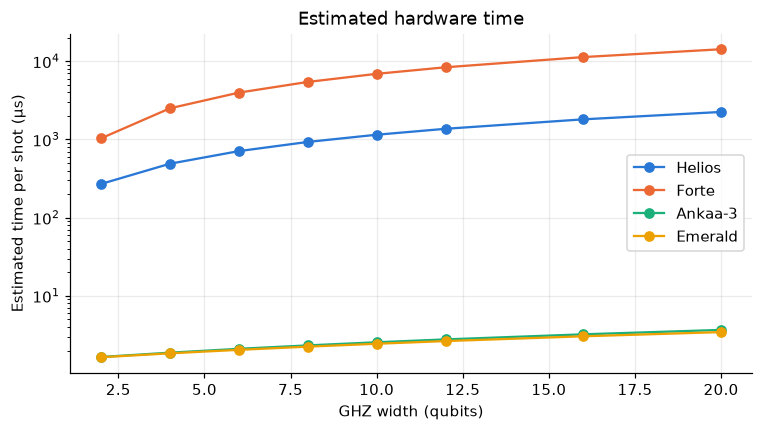

Assumed in the Emerald estimate: ['gates.cz.duration_ns', 'gates.prx.duration_ns', 'readout.duration_ns']


In [9]:
widths = [2, 4, 6, 8, 10, 12, 16, 20]
times = {b: [run(b, ghz(n), routing=True, shots=16)["compilation"]["hardware_time_estimate"]["circuit_duration_us"] for n in widths]
         for b in BACKENDS}

fig, ax = plt.subplots(figsize=(8, 4))
for backend, values in times.items():
    ax.plot(widths, values, "o-", color=COLORS[backend], label=NAMES[backend])
ax.set(yscale="log", xlabel="GHZ width (qubits)", ylabel="Estimated time per shot (µs)", title="Estimated hardware time")
ax.legend()
plt.show()

print("Assumed in the Emerald estimate:", results["iqm_emerald"]["compilation"]["hardware_time_estimate"]["assumed_parameters"])

## Strict mode

`compilation="strict"` accepts native gates only, as a real pulse-level interface would. A standard gate is rejected
with an explanation, and a native program runs unchanged.

In [10]:
rejected = run("quantinuum_helios", bell(), compilation="strict")
print(rejected["http_status"], rejected["error"]["type"])
print(rejected["error"]["message"])

422 NativeGateError
'h' (line 5) lowers to non-native operation 'U'; quantinuum_helios natives are ['rz', 'rzz', 'u1q', 'zzmax']


200 {'u1q': 3, 'zzmax': 1}


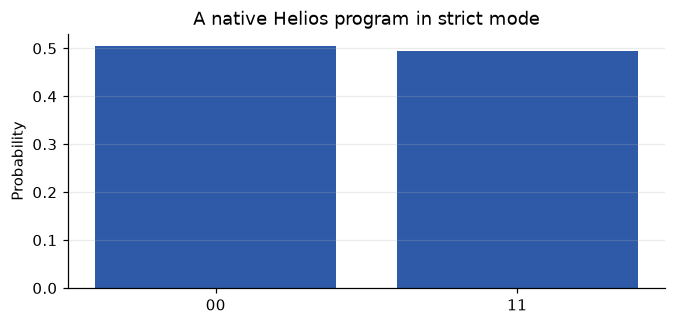

In [11]:
native_program = """OPENQASM 2.0;
qreg q[2];
creg c[2];
u1q(pi/2, -pi/2) q[0];
u1q(pi/2, -pi/2) q[1];
zzmax q[0],q[1];
u1q(pi/2, pi) q[1];
measure q -> c;
"""
accepted = run("quantinuum_helios", native_program, compilation="strict")
print(accepted["http_status"], accepted["compilation"]["native_gate_histogram"])
plot_counts(accepted["result"]["counts"], "A native Helios program in strict mode");